# Waveforms Project 2025–2026
**Course:** Machine Learning  
**Objective:** Evaluate k-Nearest Neighbors (kNN) and Data Reduction methods on the Waveform dataset.


In [145]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

### 🏁 Load and Preprocess Data  


In [136]:
df = pd.read_csv('waveform.data', header=None, sep=',')
print(df.shape)
df.head()


(5000, 22)


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
0,-1.23,-1.56,-1.75,-0.28,0.60,2.22,0.85,0.21,-0.20,0.89,...,2.89,7.75,4.59,3.15,5.12,3.32,1.20,0.24,-0.56,2
1,-0.69,2.43,0.61,2.08,2.30,3.25,5.52,4.55,2.97,2.22,...,1.24,1.89,1.88,-1.34,0.83,1.41,1.78,0.60,2.42,1
2,-0.12,-0.94,1.29,2.59,2.42,3.55,4.94,3.25,1.90,2.07,...,2.50,0.12,1.41,2.78,0.64,0.62,-0.01,-0.79,-0.12,0
3,0.86,0.29,2.19,-0.02,1.13,2.51,2.37,5.45,5.45,4.84,...,2.58,1.40,1.24,1.41,1.07,-1.43,2.84,-1.18,1.12,1
4,1.16,0.37,0.40,-0.59,2.66,1.00,2.69,4.06,5.34,3.53,...,4.30,1.84,1.73,0.21,-0.18,0.13,-0.21,-0.80,-0.68,1


In [101]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values
unique, counts = np.unique(y, return_counts=True)
print(dict(zip(unique, counts)))


{0: 1657, 1: 1647, 2: 1696}


### 🏁 Split into 4000 (train) and 1000 (test)

In [102]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=4000, test_size=1000, stratify=y, random_state=42
)


### 🏁 KNN

In [103]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)


In [138]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score


ks = list(range(1, 101, 2))   # odd k from 1 to 101
cv_scores = []
for k in ks:
    clf = KNeighborsClassifier(n_neighbors=k, metric='euclidean', n_jobs=-1)
    scores = cross_val_score(clf, X_train_s, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_scores.append(scores.mean())


In [139]:
best_k = ks[np.argmax(cv_scores)]
knn = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1).fit(X_train_s, y_train)
test_acc = knn.score(X_test_s, y_test)
print(best_k, test_acc)


79 0.835


### 🏁 Tune k using 5-Fold Cross-Validation

In [140]:
cv_scores = []
test_scores = []
cv_vars = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    scores = cross_val_score(knn, X_train_s, y_train, cv=5, scoring='accuracy', n_jobs=-1)
    cv_scores.append(scores.mean())
    knn.fit(X_train_s, y_train)
    test_scores.append(knn.score(X_test_s, y_test))
    cv_vars.append(scores.var())
    

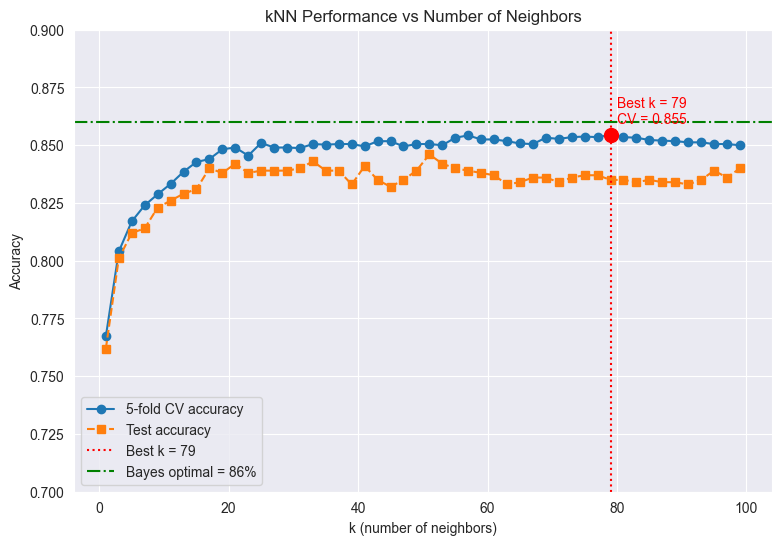

Best k = 79
Best 5-fold CV accuracy = 0.8545
Test accuracy at best k = 0.8350
Bayes optimal accuracy = 0.86
Gap to Bayes limit = 0.0250


In [141]:
# Identify best k
best_index = np.argmax(cv_scores)
best_k = ks[best_index]
best_cv = cv_scores[best_index]
best_test = test_scores[best_index]

plt.figure(figsize=(9,6))
plt.plot(ks, cv_scores, marker='o', label='5-fold CV accuracy')
plt.plot(ks, test_scores, marker='s', linestyle='--', label='Test accuracy')
plt.axvline(best_k, color='red', linestyle=':', label=f'Best k = {best_k}')
plt.scatter(best_k, best_cv, color='red', s=100, zorder=5)

bayes_optimal = 0.86
plt.axhline(bayes_optimal, color='green', linestyle='-.', label='Bayes optimal = 86%')

# Label best point
plt.text(best_k+1, best_cv+0.005, f"Best k = {best_k}\nCV = {best_cv:.3f}", color='red')

plt.title('kNN Performance vs Number of Neighbors')
plt.xlabel('k (number of neighbors)')
plt.ylabel('Accuracy')
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(True)
plt.show()

print(f"Best k = {best_k}")
print(f"Best 5-fold CV accuracy = {best_cv:.4f}")
print(f"Test accuracy at best k = {best_test:.4f}")
print(f"Bayes optimal accuracy = {bayes_optimal}")
print(f"Gap to Bayes limit = {bayes_optimal - best_test:.4f}")

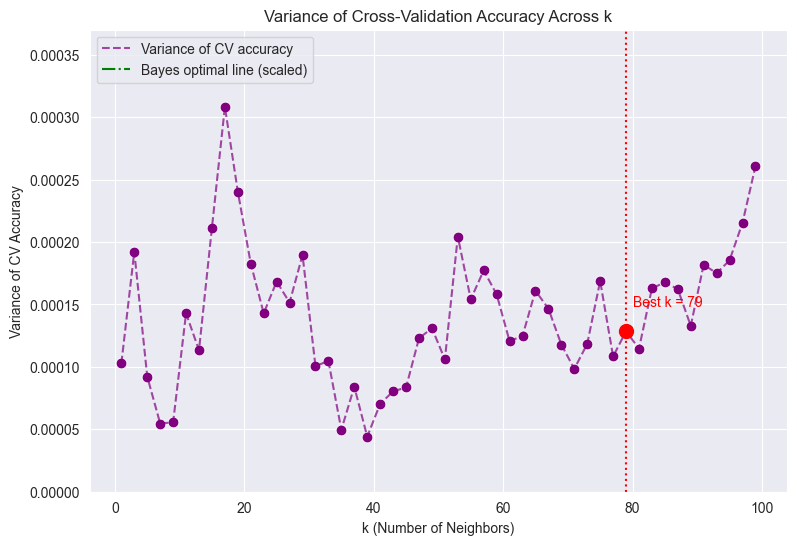

Best k = 79
Variance at best k = 0.000128


In [146]:
sns.set_style('darkgrid')

plt.figure(figsize=(9,6))
sns.scatterplot(x=ks, y=cv_vars, color='purple', s=60)
plt.plot(ks, cv_vars, linestyle='--', color='purple', alpha=0.7, label='Variance of CV accuracy')

best_k = ks[best_index]
best_var = cv_vars[best_index]
plt.axvline(best_k, color='red', linestyle=':')
plt.scatter(best_k, best_var, color='red', s=100, zorder=5)
plt.text(best_k + 1, best_var + 0.00002, f"Best k = {best_k}", color='red')


bayes_optimal = 0.86
plt.axhline(bayes_optimal/100, color='green', linestyle='-.', label='Bayes optimal line (scaled)')

plt.title("Variance of Cross-Validation Accuracy Across k")
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Variance of CV Accuracy")
plt.ylim(0, max(cv_vars)*1.2)
plt.grid(True)
plt.legend()
plt.show()

print(f"Best k = {best_k}")
print(f"Variance at best k = {best_var:.6f}")


### 🏁 Bias–Variance Trade-off

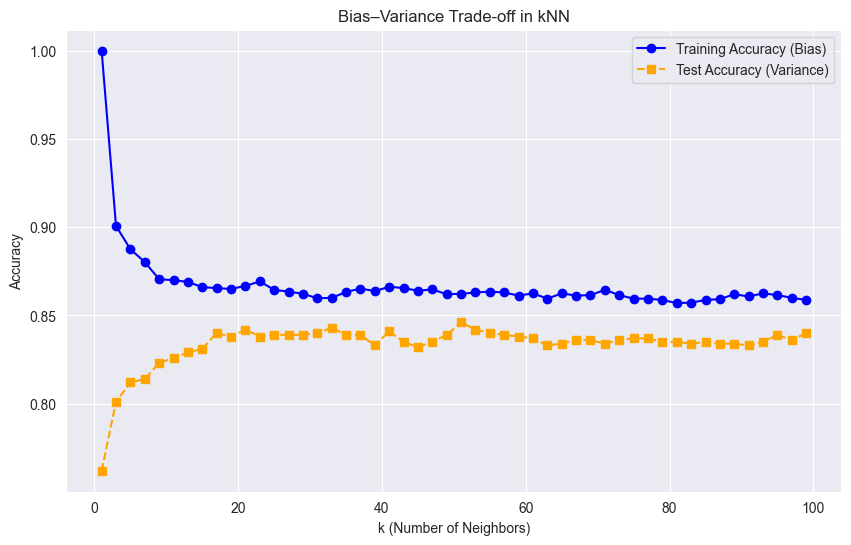

In [155]:
sns.set_style('darkgrid')

ks = list(range(1, 101, 2))
train_acc = []
test_acc = []
cv_var = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s, y_train)
    train_acc.append(knn.score(X_train_s, y_train))
    test_acc.append(knn.score(X_test_s, y_test))
    
    cv_scores = cross_val_score(knn, X_train_s, y_train, cv=5)
    cv_var.append(np.var(cv_scores))

plt.figure(figsize=(10,6))
plt.plot(ks, train_acc, 'o-', color='blue', label='Training Accuracy (Bias)')
plt.plot(ks, test_acc, 's--', color='orange', label='Test Accuracy (Variance)')
plt.title("Bias–Variance Trade-off in kNN")
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


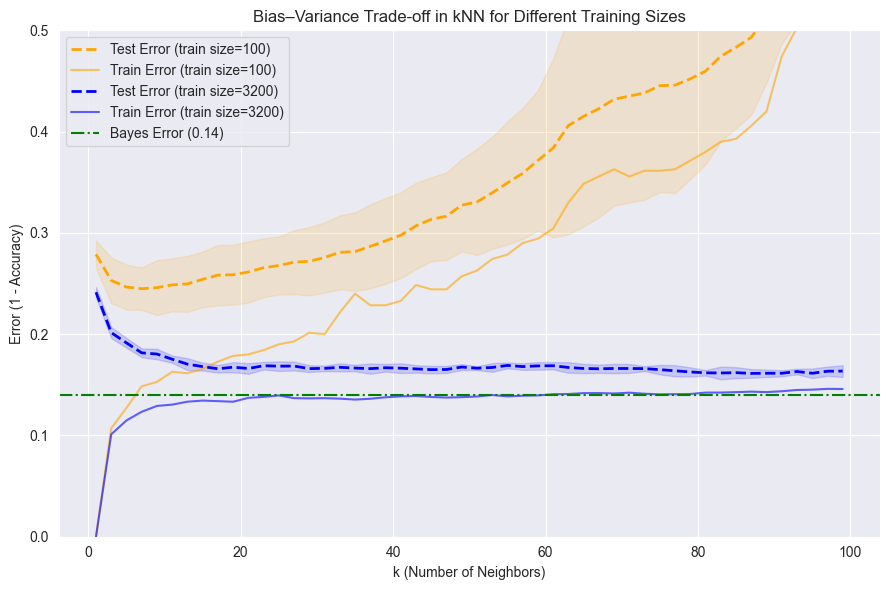

In [156]:
# === Combined Bias–Variance Trade-off for Training Sizes 100 and 3200 ===
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from time import time

def bias_variance_by_train_size(X_train_full, y_train_full, X_test, y_test,
                                train_sizes=(100, 3200), ks=None, n_repeats=5, random_state=42):
    rng = np.random.default_rng(random_state)
    if ks is None:
        ks = list(range(1, 101, 2))
    results = {}
    n_total = len(X_train_full)
    
    for t in train_sizes:
        train_errs = np.zeros((n_repeats, len(ks)))
        test_errs  = np.zeros((n_repeats, len(ks)))
        for r in range(n_repeats):
            idx = rng.choice(n_total, size=t, replace=False)
            X_sub = X_train_full[idx]
            y_sub = y_train_full[idx]
            
            for j, k in enumerate(ks):
                knn = KNeighborsClassifier(n_neighbors=k)
                knn.fit(X_sub, y_sub)
                train_errs[r, j] = 1 - knn.score(X_sub, y_sub)
                test_errs[r, j]  = 1 - knn.score(X_test, y_test)
        
        results[t] = {
            'ks': ks,
            'train_mean': train_errs.mean(axis=0),
            'train_std':  train_errs.std(axis=0),
            'test_mean':  test_errs.mean(axis=0),
            'test_std':   test_errs.std(axis=0)
        }
    return results

# --- Run experiment ---
ks = list(range(1, 101, 2))  # Odd k values (1, 3, 5, ..., 49)
res = bias_variance_by_train_size(X_train_s, y_train, X_test_s, y_test,
                                  train_sizes=(100, 3200), ks=ks, n_repeats=7, random_state=0)

plt.figure(figsize=(9,6))
colors = {100: 'orange', 3200: 'blue'}

for t in (100, 3200):
    d = res[t]
    plt.plot(d['ks'], d['test_mean'], label=f'Test Error (train size={t})', color=colors[t], linestyle='--', linewidth=2)
    plt.fill_between(d['ks'], d['test_mean'] - d['test_std'], d['test_mean'] + d['test_std'], color=colors[t], alpha=0.15)
    plt.plot(d['ks'], d['train_mean'], label=f'Train Error (train size={t})', color=colors[t], linestyle='-', alpha=0.6)

# Add Bayesian reference line
plt.axhline(1 - 0.86, color='green', linestyle='-.', label='Bayes Error (0.14)')

plt.title('Bias–Variance Trade-off in kNN for Different Training Sizes')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('Error (1 - Accuracy)')
plt.ylim(0.0, 0.5)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


### 🏁 Data Reduction Algorithms


In [119]:
def condensed_nn(X, y):
    S_idx = [0]                
    changed = True
    while changed:
        changed = False
        for i in range(len(X)):
            if i in S_idx: continue
            # find nearest in S
            nn = find_nn_index(X[i], X[S_idx])
            if y[nn_in_S] != y[i]:
                S_idx.append(i)
                changed = True
    return X[S_idx], y[S_idx]


### 🏁 CNN

In [151]:
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from time import time

def condensed_nn_improved(X, y, start_fraction=0.02, random_state=42):
    """
    Improved CNN algorithm with random initialization.
    start_fraction: fraction of samples to start with (default 2%)
    """
    rng = np.random.default_rng(random_state)
    n_samples = len(X)
    n_start = max(1, int(start_fraction * n_samples))

    # Randomly pick a small subset to start with
    S_idx = rng.choice(n_samples, size=n_start, replace=False).tolist()
    changed = True

    while changed:
        changed = False
        nbrs = NearestNeighbors(n_neighbors=1, algorithm='auto').fit(X[S_idx])
        for i in range(n_samples):
            if i in S_idx:
                continue
            _, nn_idx = nbrs.kneighbors([X[i]])
            nn_in_S = nn_idx[0][0]
            if y[S_idx[nn_in_S]] != y[i]:
                S_idx.append(i)
                changed = True

    return np.array(S_idx)


# --- Run experiment ---
start_time = time()
S_idx = condensed_nn_improved(X_train_s, y_train, start_fraction=0.05)  # start with 5%
end_time = time()

X_reduced, y_reduced = X_train_s[S_idx], y_train[S_idx]

print("=== Improved CNN Reduction ===")
print(f"Original training size: {len(X_train_s)}")
print(f"Reduced training size:  {len(X_reduced)}")
print(f"Reduction rate:         {len(X_reduced)/len(X_train_s):.2%}")
print(f"Time taken:              {end_time - start_time:.2f} seconds")

# --- Accuracy comparison ---
knn_full = KNeighborsClassifier(n_neighbors=1)
knn_full.fit(X_train_s, y_train)
acc_full = knn_full.score(X_test_s, y_test)

knn_reduced = KNeighborsClassifier(n_neighbors=1)
knn_reduced.fit(X_reduced, y_reduced)
acc_reduced = knn_reduced.score(X_test_s, y_test)

print("\n=== 1-NN Accuracy Comparison ===")
print(f"Before reduction: {acc_full:.4f}")
print(f"After reduction:  {acc_reduced:.4f}")
print(f"Reduction impact: {acc_reduced - acc_full:+.4f}")


=== Improved CNN Reduction ===
Original training size: 4000
Reduced training size:  2110
Reduction rate:         52.75%
Time taken:              108.80 seconds

=== 1-NN Accuracy Comparison ===
Before reduction: 0.7620
After reduction:  0.7290
Reduction impact: -0.0330


Computing accuracy for each k (CNN reduction)...


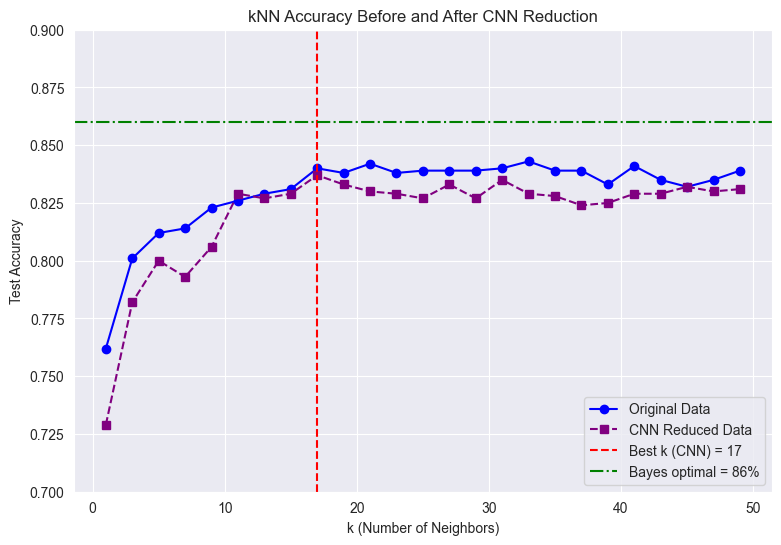

Best k (original data): 33, accuracy = 0.8430
Best k (CNN reduced): 17, accuracy = 0.8370
Reduction rate: 47.25%


In [152]:


ks = list(range(1, 101, 2))  # odd k values
acc_full_list = []
acc_cnn_list = []

print("Computing accuracy for each k (CNN reduction)...")

for k in ks:
    # Full data
    knn_full = KNeighborsClassifier(n_neighbors=k)
    knn_full.fit(X_train_s, y_train)
    acc_full_list.append(knn_full.score(X_test_s, y_test))
    
    # CNN-reduced data
    knn_cnn = KNeighborsClassifier(n_neighbors=k)
    knn_cnn.fit(X_reduced, y_reduced)
    acc_cnn_list.append(knn_cnn.score(X_test_s, y_test))

# Find best k for each
best_k_full_cnn = ks[np.argmax(acc_full_list)]
best_acc_full_cnn = max(acc_full_list)
best_k_cnn = ks[np.argmax(acc_cnn_list)]
best_acc_cnn = max(acc_cnn_list)

# --- Plot ---
plt.figure(figsize=(9,6))
plt.plot(ks, acc_full_list, marker='o', color='blue', label='Original Data')
plt.plot(ks, acc_cnn_list, marker='s', linestyle='--', color='purple', label='CNN Reduced Data')
plt.axvline(best_k_cnn, color='red', linestyle='--', label=f'Best k (CNN) = {best_k_cnn}')
plt.axhline(0.86, color='green', linestyle='-.', label='Bayes optimal = 86%')

plt.title("kNN Accuracy Before and After CNN Reduction")
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(True)
plt.show()

print(f"Best k (original data): {best_k_full_cnn}, accuracy = {best_acc_full_cnn:.4f}")
print(f"Best k (CNN reduced): {best_k_cnn}, accuracy = {best_acc_cnn:.4f}")
print(f"Reduction rate: {(1 - len(X_reduced)/len(X_train_s)) * 100:.2f}%")


### 🏁 RNN

In [148]:
from sklearn.metrics import accuracy_score

def reduced_nn_fast(X, y, max_remove=0.3, random_state=42):
    """
    Optimized Reduced Nearest Neighbor (RNN) algorithm.
    Removes samples that do not affect classification accuracy.
    Parameters:
        X, y           : training data
        max_remove     : fraction of samples to test for removal (default 30%)
        random_state   : reproducibility
    Returns:
        X_reduced, y_reduced, reduction_rate
    """
    rng = np.random.default_rng(random_state)
    n_samples = len(X)
    
    # Start with full dataset
    indices = np.arange(n_samples)
    removable = rng.choice(indices, size=int(max_remove * n_samples), replace=False)
    
    knn = KNeighborsClassifier(n_neighbors=1)
    knn.fit(X, y)
    base_pred = knn.predict(X)
    base_acc = accuracy_score(y, base_pred)
    
    kept_indices = list(indices)
    removed = 0

    for idx in removable:
        temp_indices = [i for i in kept_indices if i != idx]
        knn.fit(X[temp_indices], y[temp_indices])
        new_pred = knn.predict(X[temp_indices])
        new_acc = accuracy_score(y[temp_indices], new_pred)
        
        # If accuracy does not decrease, remove the point
        if new_acc >= base_acc:
            kept_indices.remove(idx)
            removed += 1
    
    reduction_rate = 1 - len(kept_indices) / n_samples
    return X[kept_indices], y[kept_indices], reduction_rate


# --- Run the RNN reduction experiment ---
start_time = time()
X_rnn, y_rnn, reduction_rate = reduced_nn_fast(X_train_s, y_train, max_remove=0.4)
end_time = time()

print("=== Reduced Nearest Neighbor (Optimized) ===")
print(f"Original training size: {len(X_train_s)}")
print(f"Reduced training size:  {len(X_rnn)}")
print(f"Reduction rate:         {reduction_rate:.2%}")
print(f"Time taken:              {end_time - start_time:.2f} seconds")

# --- Evaluate 1-NN accuracy before and after reduction ---
knn_full = KNeighborsClassifier(n_neighbors=1)
knn_full.fit(X_train_s, y_train)
acc_full = knn_full.score(X_test_s, y_test)

knn_rnn = KNeighborsClassifier(n_neighbors=1)
knn_rnn.fit(X_rnn, y_rnn)
acc_rnn = knn_rnn.score(X_test_s, y_test)

print("\n=== 1-NN Accuracy Comparison ===")
print(f"Before reduction: {acc_full:.4f}")
print(f"After reduction:  {acc_rnn:.4f}")
print(f"Reduction impact: {acc_rnn - acc_full:+.4f}")


=== Reduced Nearest Neighbor (Optimized) ===
Original training size: 4000
Reduced training size:  2400
Reduction rate:         40.00%
Time taken:              115.17 seconds

=== 1-NN Accuracy Comparison ===
Before reduction: 0.7620
After reduction:  0.7570
Reduction impact: -0.0050


Computing accuracy for each k (this may take a few seconds)...


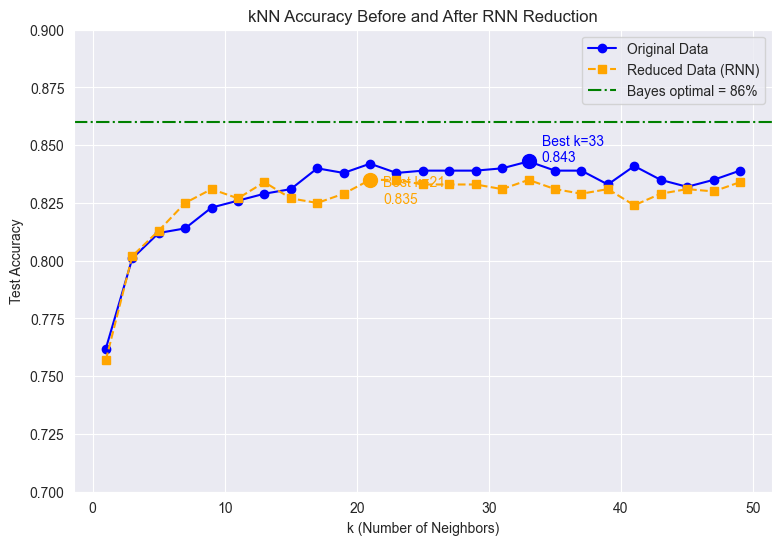

Best accuracy (original data): 0.8430 at k = 33
Best accuracy (reduced data):  0.8350 at k = 21
Reduction rate:                60.00%


In [149]:
sns.set_style('darkgrid')

ks = list(range(1, 101, 2))  # same range of k used earlier
acc_full_list = []
acc_rnn_list = []

print("Computing accuracy for each k (this may take a few seconds)...")

for k in ks:
    knn_full = KNeighborsClassifier(n_neighbors=k)
    knn_full.fit(X_train_s, y_train)
    acc_full_list.append(knn_full.score(X_test_s, y_test))
    
    knn_rnn = KNeighborsClassifier(n_neighbors=k)
    knn_rnn.fit(X_rnn, y_rnn)
    acc_rnn_list.append(knn_rnn.score(X_test_s, y_test))

# --- Find best k values ---
best_k_full = ks[np.argmax(acc_full_list)]
best_k_rnn = ks[np.argmax(acc_rnn_list)]
best_acc_full = max(acc_full_list)
best_acc_rnn = max(acc_rnn_list)

# --- Plot ---
plt.figure(figsize=(9,6))
plt.plot(ks, acc_full_list, marker='o', label='Original Data', color='blue')
plt.plot(ks, acc_rnn_list, marker='s', linestyle='--', label='Reduced Data (RNN)', color='orange')

plt.scatter(best_k_full, best_acc_full, color='blue', s=100, zorder=5)
plt.scatter(best_k_rnn, best_acc_rnn, color='orange', s=100, zorder=5)

plt.text(best_k_full + 1, best_acc_full, f"Best k={best_k_full}\n{best_acc_full:.3f}", color='blue')
plt.text(best_k_rnn + 1, best_acc_rnn - 0.01, f"Best k={best_k_rnn}\n{best_acc_rnn:.3f}", color='orange')

plt.axhline(0.86, color='green', linestyle='-.', label='Bayes optimal = 86%')

plt.title("kNN Accuracy Before and After RNN Reduction")
plt.xlabel("k (Number of Neighbors)")
plt.ylabel("Test Accuracy")
plt.ylim(0.7, 0.9)
plt.legend()
plt.grid(True)
plt.show()

print(f"Best accuracy (original data): {best_acc_full:.4f} at k = {best_k_full}")
print(f"Best accuracy (reduced data):  {best_acc_rnn:.4f} at k = {best_k_rnn}")
print(f"Reduction rate:                {len(X_rnn)/len(X_train_s):.2%}")


### 🏁 Comperision With Other Classifiers


In [158]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# Define models to compare
models = [
    ("kNN (best k)", KNeighborsClassifier(n_neighbors=best_k_full)),
    ("Decision Tree", DecisionTreeClassifier(random_state=42)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, random_state=42)),
    ("SVM (RBF kernel)", SVC(kernel='rbf', gamma='scale'))
]

results = []
for name, model in models:
    model.fit(X_train_s, y_train)
    acc = model.score(X_test_s, y_test)
    results.append((name, acc))
    print(f"{name:20s} → Test Accuracy: {acc:.4f}")

comparison_df = pd.DataFrame(results, columns=["Model", "Test Accuracy"])
comparison_df.sort_values("Test Accuracy", ascending=False, inplace=True)
comparison_df


kNN (best k)         → Test Accuracy: 0.8430
Decision Tree        → Test Accuracy: 0.7440
Random Forest        → Test Accuracy: 0.8460
SVM (RBF kernel)     → Test Accuracy: 0.8530


,Model,Test Accuracy
3,SVM (RBF kernel),0.853
2,Random Forest,0.846
0,kNN (best k),0.843
1,Decision Tree,0.744


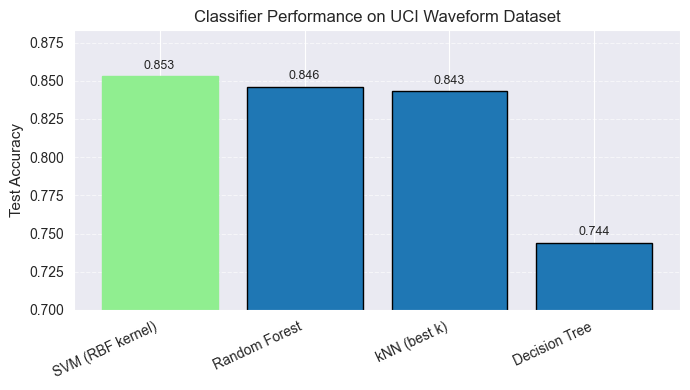

In [157]:
import matplotlib.pyplot as plt

comparison_df = comparison_df.sort_values("Test Accuracy", ascending=False).reset_index(drop=True)

# Plot
plt.figure(figsize=(7,4))
bars = plt.bar(comparison_df["Model"], comparison_df["Test Accuracy"], edgecolor='black')

best_idx = comparison_df["Test Accuracy"].idxmax()
bars[best_idx].set_color("lightgreen")

for i, acc in enumerate(comparison_df["Test Accuracy"]):
    plt.text(i, acc + 0.005, f"{acc:.3f}", ha='center', fontsize=9)

plt.ylabel("Test Accuracy", fontsize=11)
plt.ylim(0.7, max(comparison_df["Test Accuracy"]) + 0.03)
plt.title("Classifier Performance on UCI Waveform Dataset", fontsize=12)
plt.xticks(rotation=25, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


### 🏁 Conclusion

In this project, we evaluated k-Nearest Neighbors on the Waveform dataset and explored how data reduction techniques like CNN and RNN affect performance. The results show that reduction can significantly shrink the training set with only a small drop in accuracy. Among all tested models, the SVM with RBF kernel achieved the best performance (~85%), which is close to the Bayes optimal rate of 86%. Overall, the experiments confirm that careful tuning and data reduction can make kNN more efficient without major accuracy loss.
